# 第 2 章配套 Notebook：神经网络前向计算、卷积矩阵化与批归一化折叠

[![Open In Colab (main)](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/main/notion/notebooks/ch02_nn_forward_and_bn_folding.ipynb) （PR 审查期分支链接：[点此在 Colab 打开 gemini/deep-01 版](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/gemini/deep-01/notion/notebooks/ch02_nn_forward_and_bn_folding.ipynb)）

> **运行环境**：仅需 Python ≥ 3.10、`numpy`、`matplotlib`，不需要 GPU，也不依赖 PyTorch 等深度学习框架。所有矩阵每一步的中间数值均直接打印并与第 2 章正文手算结果逐位核对一致。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# 配置中文与负号显示（Windows / Linux / macOS / Colab 通用回退）
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'Arial Unicode MS', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
np.set_printoptions(precision=6, suppress=True)
print("NumPy version:", np.__version__)


NumPy version: 2.5.5


## 1. 为什么必须有非线性？两层纯线性网络退化为单层线性网络

验证 $W_2(W_1\mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2 = W_{\mathrm{eq}}\mathbf{x} + \mathbf{b}_{\mathrm{eq}}$，以及加入 $\mathrm{ReLU}$ 后产生折线决策边界。

In [2]:
W1 = np.array([[ 1.0, -2.0],
               [ 0.5,  1.0],
               [-1.0,  0.5]])   # shape (3, 2)
b1 = np.array([0.2, -0.4, 0.1]) # shape (3,)
W2 = np.array([[ 2.0, -1.0, 0.5],
               [-0.5,  2.0, 1.0]]) # shape (2, 3)
b2 = np.array([-0.1, 0.3])      # shape (2,)

W_eq = W2 @ W1
b_eq = W2 @ b1 + b2

X_batch = np.array([[ 1.0,  2.0],
                    [-1.5,  0.5],
                    [ 0.0, -1.0],
                    [ 2.5, -0.5]]) # shape (B=4, d_in=2)

# 两层无激活函数串联 vs 单层等效矩阵（批量形式 X @ W.T + b）
Y_two_linear = (X_batch @ W1.T + b1) @ W2.T + b2
Y_collapsed  = X_batch @ W_eq.T + b_eq
assert np.allclose(Y_two_linear, Y_collapsed)
print("W_eq (shape", W_eq.shape, "):\n", W_eq)
print("b_eq (shape", b_eq.shape, "):", b_eq)
print("两层线性串联与单层等效输出最大差 :", np.max(np.abs(Y_two_linear - Y_collapsed)))

# 加入 ReLU 后：不再等于任何单一线性变换
Y_with_relu = np.maximum(0.0, X_batch @ W1.T + b1) @ W2.T + b2
print("\n加入 ReLU 后的批量输出 Y (shape", Y_with_relu.shape, "):\n", Y_with_relu)


W_eq (shape (2, 2) ):
 [[ 1.   -4.75]
 [-0.5   3.5 ]]
b_eq (shape (2,) ): [ 0.75 -0.5 ]
两层线性串联与单层等效输出最大差 : 8.881784197001252e-16

加入 ReLU 后的批量输出 Y (shape (4, 2) ):
 [[-2.15   4.6  ]
 [ 0.825  2.15 ]
 [ 4.3   -0.8  ]
 [ 6.95  -0.85 ]]


## 2. 一维卷积等价于“共享权重的稀疏（Toeplitz）矩阵乘法”

复现第 2 章手算例 2.1：输入长度 5 的信号 $\mathbf{x}=[1, 2, 0, -1, 3]^\top$，卷积核 $\mathbf{k}=[1, 0, -1]$，无填充、步幅 1。

In [3]:
x_sig = np.array([1.0, 2.0, 0.0, -1.0, 3.0])
kernel = np.array([1.0, 0.0, -1.0])  # w1=1, w2=0, w3=-1

# 滑动窗口逐位计算
y_slide = np.array([
    kernel[0]*x_sig[0] + kernel[1]*x_sig[1] + kernel[2]*x_sig[2],
    kernel[0]*x_sig[1] + kernel[1]*x_sig[2] + kernel[2]*x_sig[3],
    kernel[0]*x_sig[2] + kernel[1]*x_sig[3] + kernel[2]*x_sig[4],
])

# 构造共享权重的稀疏矩阵 W_conv (shape 3x5)
W_conv = np.array([
    [1.0, 0.0, -1.0, 0.0,  0.0],
    [0.0, 1.0,  0.0, -1.0, 0.0],
    [0.0, 0.0,  1.0,  0.0, -1.0],
])
y_mat = W_conv @ x_sig

print("W_conv (shape", W_conv.shape, ", 非零元比例", np.count_nonzero(W_conv)/W_conv.size, "):\n", W_conv)
print("滑动窗口结果 :", y_slide)
print("矩阵乘法结果 :", y_mat)
assert np.allclose(y_slide, y_mat)
assert np.allclose(y_mat, np.array([1.0, 3.0, -3.0]))


W_conv (shape (3, 5) , 非零元比例 0.4 ):
 [[ 1.  0. -1.  0.  0.]
 [ 0.  1.  0. -1.  0.]
 [ 0.  0.  1.  0. -1.]]
滑动窗口结果 : [ 1.  3. -3.]
矩阵乘法结果 : [ 1.  3. -3.]


## 3. 批归一化（BatchNorm）推理期折叠进 $W$ 和 $\mathbf{b}$ 的完整验证

复现第 2 章手算例 2.2（对应 Rueckauer 等 2017 Section 3.3 公式）：
$$\tilde{W}_{ij} = \frac{\gamma_i}{\sqrt{\sigma_i^2 + \epsilon}} W_{ij}, \qquad \tilde{b}_i = \frac{\gamma_i}{\sqrt{\sigma_i^2 + \epsilon}}(b_i - \mu_i) + \beta_i$$

In [4]:
# 手算例 2.2 参数：d_in = 2, d_out = 2
W = np.array([[ 2.0, -1.0],
              [-0.5,  1.5]])
b = np.array([0.5, -1.0])

# 训练完成后冻结的统计量与可学习缩放/平移参数（取 epsilon = 0 以便手算整除，同时对比 epsilon = 1e-5）
mu     = np.array([ 1.5, -0.5])
var    = np.array([ 0.25, 4.0])   # 标准差分别为 0.5 和 2.0
gamma  = np.array([ 1.0,  3.0])
beta   = np.array([-0.2,  0.4])
eps    = 0.0

x_test = np.array([2.0, 1.0])

# 方法 A：先算线性层 z = Wx + b，再过 BN，再过 ReLU
z = W @ x_test + b
z_bn = gamma * (z - mu) / np.sqrt(var + eps) + beta
y_unfolded = np.maximum(0.0, z_bn)

# 方法 B：离线折叠 BN 到 W_tilde, b_tilde，推理时只算一次线性层 + ReLU
scale = gamma / np.sqrt(var + eps)              # shape (2,): [2.0, 1.5]
W_tilde = scale[:, None] * W                    # 每一行 i 乘以 scale[i]
b_tilde = scale * (b - mu) + beta

z_folded = W_tilde @ x_test + b_tilde
y_folded = np.maximum(0.0, z_folded)

print("线性层输出 z          =", z)
print("展开算 BN(z)          =", z_bn)
print("缩放因子 scale        =", scale)
print("折叠后权重 W_tilde    =\n", W_tilde)
print("折叠后偏置 b_tilde    =", b_tilde)
print("折叠算 W_tilde x + b  =", z_folded)
print("ReLU 输出 (展开 vs 折叠):", y_unfolded, "vs", y_folded)

assert np.allclose(z_bn, z_folded)
assert np.allclose(y_unfolded, y_folded)
assert np.allclose(W_tilde, np.array([[4.0, -2.0], [-0.75, 2.25]]))
assert np.allclose(b_tilde, np.array([-2.2, -0.35]))

# 再随机抽 100 个输入样本批量验证误差为机器精度 0
rng = np.random.default_rng(42)
X_rand = rng.normal(size=(100, 2))
diff_max = np.max(np.abs((gamma * ((X_rand @ W.T + b) - mu) / np.sqrt(var + eps) + beta) - (X_rand @ W_tilde.T + b_tilde)))
print("100 个随机样本上 BN 折叠前后最大绝对误差 :", diff_max)
assert diff_max < 1e-14


线性层输出 z          = [ 3.5 -0.5]
展开算 BN(z)          = [3.8 0.4]
缩放因子 scale        = [2.  1.5]
折叠后权重 W_tilde    =
 [[ 4.   -2.  ]
 [-0.75  2.25]]
折叠后偏置 b_tilde    = [-2.2  -0.35]
折叠算 W_tilde x + b  = [3.8 0.4]
ReLU 输出 (展开 vs 折叠): [3.8 0.4] vs [3.8 0.4]
100 个随机样本上 BN 折叠前后最大绝对误差 : 1.7763568394002505e-15


## 4. 练习配套实验区（改代码看现象：如果错把 BN 放在 ReLU 之后还能折叠进前一层吗？）

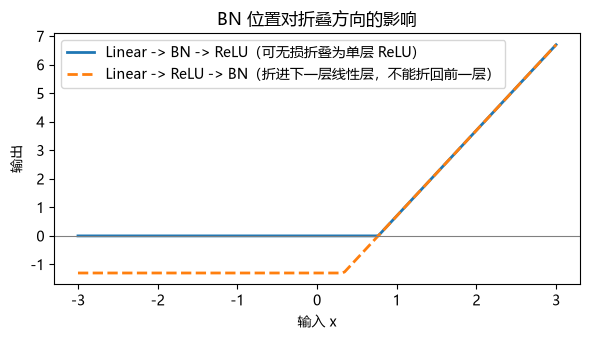

In [5]:
# 实验：对比 Linear -> BN -> ReLU（可折叠）与 Linear -> ReLU -> BN（不可直接折叠进前一层 W）
x_grid = np.linspace(-3, 3, 200)
# 单输入单神经元示例：w=1.5, b=-0.5, mu=0.5, sigma=1.0, gamma=2.0, beta=-0.3
z_1d = 1.5 * x_grid - 0.5
y_bn_before_relu = np.maximum(0.0, 2.0 * (z_1d - 0.5) / 1.0 - 0.3)
# 若 BN 在 ReLU 之后：2.0 * (ReLU(z_1d) - 0.5) - 0.3，输出会出现负数 -1.3！
y_bn_after_relu  = 2.0 * (np.maximum(0.0, z_1d) - 0.5) - 0.3

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(x_grid, y_bn_before_relu, label="Linear -> BN -> ReLU（可无损折叠为单层 ReLU）", lw=2)
ax.plot(x_grid, y_bn_after_relu, "--", label="Linear -> ReLU -> BN（折进下一层线性层，不能折回前一层）", lw=2)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("输入 x")
ax.set_ylabel("输出")
ax.set_title("BN 位置对折叠方向的影响")
ax.legend()
plt.tight_layout()
plt.show()
